# Concentration of log p: a Gaussian model imposed on turbulence

**Question.** We fit a *Gaussian* maxent model to the 1-D turbulence windows
(second-order scattering only: the energy in 9 frequency bands).
How is log p distributed (a) on the model's own samples, (b) on the real data?

**Plan.**
1. Toy: why *any* Gaussian concentrates log p (pure counting).
2. Load the results (5 seeds).
3. Check: the model samples follow the predicted law.
4. Check: the 5 seeds agree.
5. Main result: data vs model.
6. It is not a shift (log Z plays no role).
7. The tail: bursts.
8. Toy: why intermittency produces exactly this picture.
9. Summary.

Input: `saved_results/gauss_scat2_logp/all_seeds.npz` (made on JZ by `logp_gauss_scat2.py`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew, spearmanr

BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#6b6a64'   # model, data, theory
rng = np.random.default_rng(0)

## 1. Toy: why a Gaussian concentrates log p

Take the simplest Gaussian: $M$ independent $\mathcal N(0,1)$ numbers.
Then $\log p(x) = -\tfrac12 \|x\|^2 + \text{const}$.

- $\|x\|^2$ is a sum of $M$ terms, each about 1, so $\|x\|^2 \approx M \pm \sqrt{2M}$ (a $\chi^2_M$).
- Hence log p fluctuates by $\tfrac12\sqrt{2M} = \sqrt{M/2}$ nats.

For $M = 256$: $\sqrt{128} \approx 11.3$ nats. Every sample has almost the same log p:
this is **concentration**. It is pure counting, nothing to do with turbulence.

std of log p : 11.15   (prediction sqrt(M/2) = 11.31)
skewness     : -0.178  (prediction -sqrt(8/M) = -0.177)


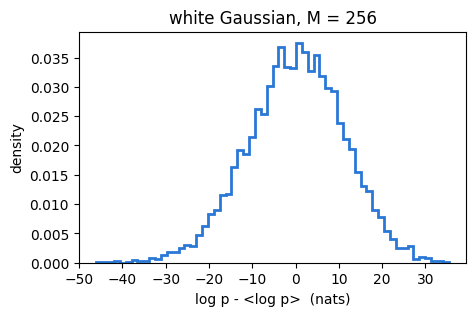

In [2]:
M = 256
x = rng.standard_normal((10000, M))     # 10000 samples of the white Gaussian
logp = -0.5 * (x**2).sum(axis=1)        # log p up to a constant
logp -= logp.mean()                     # measure from the typical sample

print(f'std of log p : {logp.std():.2f}   (prediction sqrt(M/2) = {np.sqrt(M/2):.2f})')
print(f'skewness     : {skew(logp):.3f}  (prediction -sqrt(8/M) = {-np.sqrt(8/M):.3f})')

plt.figure(figsize=(5, 3))
plt.hist(logp, bins=60, density=True, histtype='step', lw=2, color=BLUE)
plt.xlabel('log p - <log p>  (nats)'); plt.ylabel('density')
plt.title('white Gaussian, M = 256'); plt.show()

**Our model is not white**, but its log p is still a quadratic form:
$\theta\cdot\varphi(x) = -\tfrac12\, x^\top \Sigma^{-1} x$.
Change variables $y = \Sigma^{-1/2}x$ (whitening) and we are back to the toy.
So the prediction holds for *any* Gaussian, whatever $\Sigma$:
on model samples, **std(log p) = $\sqrt{M/2}$ = 11.3, skewness = −0.177**.

Physically: $x^\top\Sigma^{-1}x$ is the "whitened energy" of a window, and
log p = −½ × whitened energy. A Gaussian gives every window almost the same energy.

## 2. Load the results

For each seed $s$ (5 independent runs of the MGD sampler):

- `logp_model[s, i]` = log p of model $s$ on its own sample $i$;
- `logp_data[s, i]` = log p of model $s$ on real turbulence window $i$.

**About the unknown constant.** log p = θ·φ(x) − log Z, and we do not compute log Z.
But log Z is the *same number* for model samples and data windows of a given seed.
So we subtract, from both, the mean over that seed's model samples:
log Z cancels exactly.

Reading convention for the rest of the notebook:
**0 = a typical model sample; > 0 = more probable than typical; < 0 = less probable.**

(Existence of the Gaussian was checked in `logp_gauss_scat2.py`: the exact test
$\sum_j\theta_j|\hat\psi_j(\omega)|^2 < 0$ at every frequency passes for all seeds.)

In [3]:
d = np.load('saved_results/gauss_scat2_logp/all_seeds.npz')
seeds, M = d['seeds'], int(d['M'])
lm, ld = d['logp_model'], d['logp_data']      # shape (n_seeds, n_windows), already centred

print('seeds:', seeds, '  M =', M)
print('logp_model:', lm.shape, '  logp_data:', ld.shape)

seeds: [900 901 902 903 904]   M = 256
logp_model: (5, 10000)   logp_data: (5, 10000)


## 3. Check: the model samples follow the prediction

If the sampler produces the Gaussian correctly, each seed should give std ≈ 11.3
and skewness ≈ −0.18.

In [4]:
print(f'prediction: std {np.sqrt(M/2):.2f}, skew {-np.sqrt(8/M):.3f}\n')
for s, row in zip(seeds, lm):
    print(f'seed {s}:  std {row.std():.2f}   skew {skew(row):+.3f}')

prediction: std 11.31, skew -0.177

seed 900:  std 10.97   skew -0.189
seed 901:  std 10.93   skew -0.167
seed 902:  std 10.98   skew -0.183
seed 903:  std 10.89   skew -0.175
seed 904:  std 10.85   skew -0.147


Std is about 3 % below 11.3, skewness matches. The sampler does what the theory says:
**the model concentrates**.

## 4. Check: the 5 seeds agree on the data

Same data windows, 5 independently trained models. Do they give each window the same log p?
We use the rank correlation (Spearman), which is not dominated by a few extreme windows.

In [5]:
n = len(seeds)
rho = np.array([[spearmanr(ld[i], ld[j])[0] for j in range(n)] for i in range(n)])
print('min Spearman between seeds:', rho.min().round(5))

spread = ld.std(axis=0)     # for each window, how much the 5 seeds disagree (nats)
print(f'disagreement per window: median {np.median(spread):.3f} nats')

min Spearman between seeds: 0.9999
disagreement per window: median 0.075 nats


The seeds agree almost perfectly. From now on we pool the 5 seeds.

In [6]:
lm_all, ld_all = lm.ravel(), ld.ravel()

## 5. Main result: data vs model

Blue = log p on model samples (the concentrated peak of section 1).
Orange = log p on real turbulence windows, *same model, same zero*.

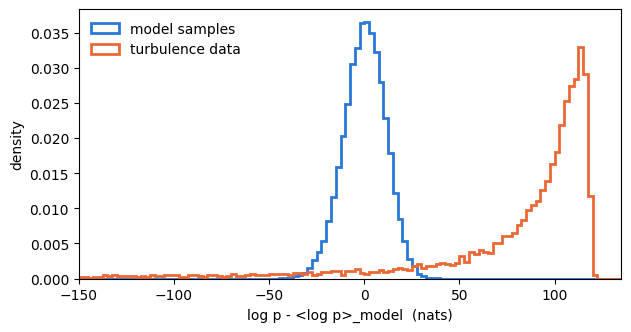

data windows off this plot (< -150): 5.8 %


In [7]:
lo, hi = -150, 135
bins = np.linspace(lo, hi, 115)

plt.figure(figsize=(7, 3.5))
plt.hist(lm_all, bins=bins, density=True, histtype='step', lw=2, color=BLUE, label='model samples')
plt.hist(ld_all, bins=bins, density=True, histtype='step', lw=2, color=ORANGE, label='turbulence data')
plt.xlabel('log p - <log p>_model  (nats)'); plt.ylabel('density')
plt.xlim(lo, hi); plt.legend(frameon=False); plt.show()

print(f'data windows off this plot (< {lo}): {100*(ld_all < lo).mean():.1f} %')

In [8]:
print(f'median log p, model samples : {np.median(lm_all):+7.1f}')
print(f'median log p, data          : {np.median(ld_all):+7.1f}\n')

print(f'data more probable than EVERY model sample : {100*(ld_all > lm_all.max()).mean():.1f} %')
print(f'data less probable than EVERY model sample : {100*(ld_all < lm_all.min()).mean():.1f} %')

median log p, model samples :    +0.3
median log p, data          :   +97.3

data more probable than EVERY model sample : 80.2 %
data less probable than EVERY model sample : 9.3 %


**Reading.** The data are *not* in the model's concentrated band:

- most windows sit far to the **right** (≈ +97 nats): the model finds them more probable
  than anything it generates itself;
- a minority sits far to the **left**: the model finds them extremely improbable.

Very few data windows look like a typical model sample.

## 6. It is not a shift

Could the orange curve just be the blue one moved by a constant (e.g. a wrong log Z)? No:

1. log Z cancelled in section 2: both curves use the same zero.
2. A shift moves the mean. But the **means are equal**:

In [9]:
print(f'mean log p, model samples: {lm_all.mean():+.2f}')
print(f'mean log p, data         : {ld_all.mean():+.2f}')

mean log p, model samples: -0.00
mean log p, data         : +0.24


This equality is forced by the fit: maxent matches the moments,
$\mathbb E_{\rm data}[\varphi] = \mathbb E_{\rm model}[\varphi]$, hence
$\mathbb E_{\rm data}[\theta\cdot\varphi] = \mathbb E_{\rm model}[\theta\cdot\varphi]$.

So the data have the **same mean but a different shape**: a peak on the right,
balanced by a very long tail on the left. That is what we look at next.

## 7. The tail: bursts

The left tail goes down to tens of thousands of nats; a linear histogram cannot show it.
Instead we plot, for each threshold $t$, the **fraction of windows with log p < −t**,
on log-log axes.

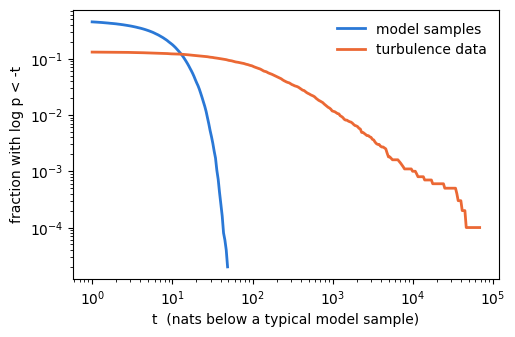

data with log p < -  100: 7.40 %
data with log p < - 1000: 1.18 %
data with log p < -10000: 0.10 %
model samples never go below -51


In [10]:
t = np.logspace(0, 5, 300)
plt.figure(figsize=(5.5, 3.5))
for arr, c, lab in [(lm_all, BLUE, 'model samples'), (ld_all, ORANGE, 'turbulence data')]:
    frac = np.array([(arr < -tt).mean() for tt in t])
    keep = frac > 0
    plt.loglog(t[keep], frac[keep], color=c, lw=2, label=lab)
plt.xlabel('t  (nats below a typical model sample)')
plt.ylabel('fraction with log p < -t')
plt.legend(frameon=False); plt.show()

for tt in [100, 1000, 10000]:
    print(f'data with log p < -{tt:>5}: {100*(ld_all < -tt).mean():.2f} %')
print(f'model samples never go below {lm_all.min():.0f}')

The model stops at about 50 nats; the data continue over 3 more decades.
These windows are the **bursts**: windows with an energy the Gaussian considers impossible.

## 8. Toy: why intermittency gives exactly this picture

Recall: for a Gaussian, log p = −½ × (whitened energy).
The fit fixes the **average** energy of the data to the model's (section 6).

Turbulence is **intermittent**: energy is shared very unequally between windows.
Toy version: each window = white noise × a random amplitude $a$,
with $a^2$ log-normal and $\mathbb E[a^2] = 1$ (same average energy as the model).

- most windows have $a^2 < 1$: calmer than average → log p **above** the model's band;
- a few have $a^2 \gg 1$: bursts → log p **far below**.

mean log p: model +0.0, intermittent toy +2.5
median    : model +0.3, intermittent toy +87.6


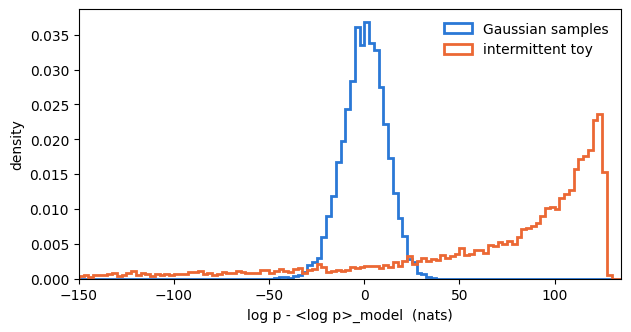

In [11]:
sig = 1.5                                                     # how intermittent (0 = Gaussian)
a2 = np.exp(sig * rng.standard_normal(10000) - sig**2 / 2)    # log-normal, mean exactly 1
x_int = np.sqrt(a2)[:, None] * rng.standard_normal((10000, M))

logp_int = -0.5 * (x_int**2).sum(axis=1)                      # log p under the white Gaussian
ref = -0.5 * (x**2).sum(axis=1)                               # its own samples (section 1)
logp_int -= ref.mean(); ref -= ref.mean()                     # same zero for both

print(f'mean log p: model {ref.mean():+.1f}, intermittent toy {logp_int.mean():+.1f}')
print(f'median    : model {np.median(ref):+.1f}, intermittent toy {np.median(logp_int):+.1f}')

plt.figure(figsize=(7, 3.5))
plt.hist(ref, bins=bins, density=True, histtype='step', lw=2, color=BLUE, label='Gaussian samples')
plt.hist(logp_int, bins=bins, density=True, histtype='step', lw=2, color=ORANGE, label='intermittent toy')
plt.xlabel('log p - <log p>_model  (nats)'); plt.ylabel('density')
plt.xlim(lo, hi); plt.legend(frameon=False); plt.show()

A one-parameter toy reproduces the turbulence picture: peak to the right, long tail
to the left, same mean (up to the sampling noise of the heavy tail). **The orange peak on the right and the tail on the left are the
same phenomenon**: the energy carried by the bursts is missing from the ordinary windows.

## 9. Summary

- **The Gaussian concentrates**: on its own samples log p has width $\sqrt{M/2} \approx 11$ nats,
  as counting predicts; all seeds agree.
- **The data are not in that band**: most windows are calmer (log p ≈ +97),
  a few % are bursts (log p down to −70 000). Same mean, different shape: not a shift.
- **Cause: intermittency.** The Gaussian only sees energy, and turbulence distributes energy
  very unevenly between windows.

**Next.** Same plot for the full `turbulence_final` model: is log p on its own samples
wide like the data, and do the data fall inside it?